In [9]:
!pip install nltk spacy
!python -m spacy download en_core_web_sm
!pip install svgling

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 34.5 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [svgling]


In [20]:
import nltk
import spacy
import matplotlib.pyplot as plt

from nltk import pos_tag, word_tokenize


# Download NLTK resources
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('punkt_tab')

# Load spaCy English model
nlp = spacy.load("en_core_web_sm")

print("Libraries loaded successfully!")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Libraries loaded successfully!


In [21]:
sentences = [
    "The cat sleeps on the mat.",
    "The students are studying natural language processing.",
    "John bought a new laptop yesterday.",
    "The beautiful flowers are growing in the garden.",
    "She is reading a book."
]

print("Input Sentences:")
for i, sentence in enumerate(sentences, 1):
    print(i, sentence)

Input Sentences:
1 The cat sleeps on the mat.
2 The students are studying natural language processing.
3 John bought a new laptop yesterday.
4 The beautiful flowers are growing in the garden.
5 She is reading a book.


In [22]:
print("PART OF SPEECH TAGGING\n")

for sentence in sentences:

    print("\nSentence:", sentence)

    tokens = word_tokenize(sentence)

    tagged_words = pos_tag(tokens)

    print("POS Tags:")

    for word, tag in tagged_words:
        print(f"{word:15} --> {tag}")

PART OF SPEECH TAGGING


Sentence: The cat sleeps on the mat.
POS Tags:
The             --> DT
cat             --> NN
sleeps          --> VBZ
on              --> IN
the             --> DT
mat             --> NN
.               --> .

Sentence: The students are studying natural language processing.
POS Tags:
The             --> DT
students        --> NNS
are             --> VBP
studying        --> VBG
natural         --> JJ
language        --> NN
processing      --> NN
.               --> .

Sentence: John bought a new laptop yesterday.
POS Tags:
John            --> NNP
bought          --> VBD
a               --> DT
new             --> JJ
laptop          --> NN
yesterday       --> NN
.               --> .

Sentence: The beautiful flowers are growing in the garden.
POS Tags:
The             --> DT
beautiful       --> JJ
flowers         --> NNS
are             --> VBP
growing         --> VBG
in              --> IN
the             --> DT
garden          --> NN
.               --> .

Senten

In [23]:
from spacy import displacy

for sentence in sentences:

    doc = nlp(sentence)

    print("\nSentence:", sentence)
    print("\nDependency Relationships:")

    for token in doc:
        print(
            f"{token.text:12} "
            f"Dependency: {token.dep_:12} "
            f"Head: {token.head.text:12} "
            f"POS: {token.pos_}"
        )

    # Display dependency graph
    displacy.render(
        doc,
        style="dep",
        jupyter=True,
        options={"compact": True}
    )


Sentence: The cat sleeps on the mat.

Dependency Relationships:
The          Dependency: det          Head: cat          POS: DET
cat          Dependency: nsubj        Head: sleeps       POS: NOUN
sleeps       Dependency: ROOT         Head: sleeps       POS: VERB
on           Dependency: prep         Head: sleeps       POS: ADP
the          Dependency: det          Head: mat          POS: DET
mat          Dependency: pobj         Head: on           POS: NOUN
.            Dependency: punct        Head: sleeps       POS: PUNCT



Sentence: The students are studying natural language processing.

Dependency Relationships:
The          Dependency: det          Head: students     POS: DET
students     Dependency: nsubj        Head: studying     POS: NOUN
are          Dependency: aux          Head: studying     POS: AUX
studying     Dependency: ROOT         Head: studying     POS: VERB
natural      Dependency: amod         Head: language     POS: ADJ
language     Dependency: compound     Head: processing   POS: NOUN
processing   Dependency: dobj         Head: studying     POS: NOUN
.            Dependency: punct        Head: studying     POS: PUNCT



Sentence: John bought a new laptop yesterday.

Dependency Relationships:
John         Dependency: nsubj        Head: bought       POS: PROPN
bought       Dependency: ROOT         Head: bought       POS: VERB
a            Dependency: det          Head: laptop       POS: DET
new          Dependency: amod         Head: laptop       POS: ADJ
laptop       Dependency: dobj         Head: bought       POS: NOUN
yesterday    Dependency: npadvmod     Head: bought       POS: NOUN
.            Dependency: punct        Head: bought       POS: PUNCT



Sentence: The beautiful flowers are growing in the garden.

Dependency Relationships:
The          Dependency: det          Head: flowers      POS: DET
beautiful    Dependency: amod         Head: flowers      POS: ADJ
flowers      Dependency: nsubj        Head: growing      POS: NOUN
are          Dependency: aux          Head: growing      POS: AUX
growing      Dependency: ROOT         Head: growing      POS: VERB
in           Dependency: prep         Head: growing      POS: ADP
the          Dependency: det          Head: garden       POS: DET
garden       Dependency: pobj         Head: in           POS: NOUN
.            Dependency: punct        Head: growing      POS: PUNCT



Sentence: She is reading a book.

Dependency Relationships:
She          Dependency: nsubj        Head: reading      POS: PRON
is           Dependency: aux          Head: reading      POS: AUX
reading      Dependency: ROOT         Head: reading      POS: VERB
a            Dependency: det          Head: book         POS: DET
book         Dependency: dobj         Head: reading      POS: NOUN
.            Dependency: punct        Head: reading      POS: PUNCT


Phrase Structure Tree:

(S
  (NP (Det The) (N cat))
  (VP (V sleeps) (PP (Prep on) (NP (Det the) (N mat)))))
              S                        
      ________|__________               
     |                   VP            
     |         __________|___           
     |        |              PP        
     |        |      ________|___       
     NP       |     |            NP    
  ___|___     |     |         ___|___   
Det      N    V    Prep     Det      N 
 |       |    |     |        |       |  
The     cat sleeps  on      the     mat



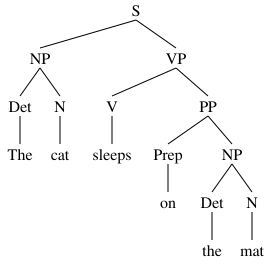

In [24]:
import nltk
from nltk import CFG
from nltk.parse import ChartParser
from IPython.display import display

grammar = CFG.fromstring("""
S -> NP VP

NP -> Det N
NP -> Det Adj N
NP -> ProperN
NP -> Pronoun

VP -> V
VP -> V NP
VP -> V PP
VP -> V NP PP

PP -> Prep NP

Det -> 'the' | 'a' | 'The'
N -> 'cat' | 'mat' | 'book' | 'garden' | 'flowers'
N -> 'laptop' | 'students'
Adj -> 'beautiful' | 'new' | 'natural'
V -> 'sleeps' | 'reading' | 'growing' | 'studying' | 'bought'
Prep -> 'on' | 'in'
ProperN -> 'John'
Pronoun -> 'She'
""")

parser = ChartParser(grammar)

test_sentence = "The cat sleeps on the mat"

tokens = test_sentence.split()

print("Phrase Structure Tree:\n")

for tree in parser.parse(tokens):

    print(tree)

    # Display tree as text
    tree.pretty_print()

    # Display tree graphically inside Google Colab
    display(nltk.Tree.fromstring(str(tree)))

PHRASE STRUCTURE TREES


Sentence: The cat sleeps on the mat.

Tree:
              S                        
      ________|__________               
     |                   VP            
     |         __________|___           
     |        |              PP        
     |        |      ________|___       
     NP       |     |            NP    
  ___|___     |     |         ___|___   
Det      N    V    Prep     Det      N 
 |       |    |     |        |       |  
the     cat sleeps  on      the     mat



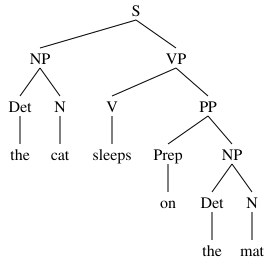


Sentence: The students are studying natural language processing.

Tree:
                        S                                
      __________________|________                         
     |                           VP                      
     |             ______________|_______                 
     NP           |     |                NP              
  ___|_____       |     |         _______|_________       
Det        N     Aux    V       Adj      N         N     
 |         |      |     |        |       |         |      
the     students are studying natural language processing



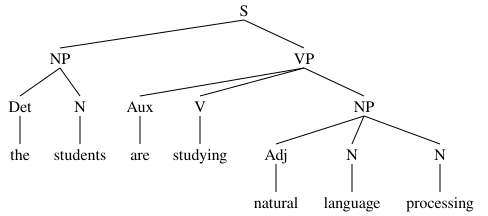


Sentence: John bought a new laptop yesterday.

Tree:
                S                      
    ____________|___                    
   |                VP                 
   |       _________|_____________      
   NP     |         NP            |    
   |      |      ___|____         |     
ProperN   V    Det Adj   N       Adv   
   |      |     |   |    |        |     
  john  bought  a  new laptop yesterday



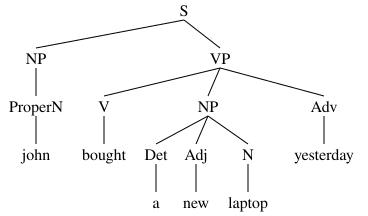


Sentence: The beautiful flowers are growing in the garden.

Tree:
                       S                             
         ______________|___________                   
        |                          VP                
        |               ___________|____              
        |              |     |          PP           
        |              |     |      ____|___          
        NP             |     |     |        NP       
  ______|________      |     |     |     ___|____     
Det    Adj       N    Aux    V    Prep Det       N   
 |      |        |     |     |     |    |        |    
the beautiful flowers are growing  in  the     garden



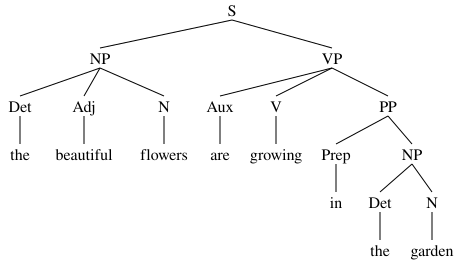


Sentence: She is reading a book.

Tree:
         S                      
    _____|_____                  
   |           VP               
   |      _____|_________        
   NP    |     |         NP     
   |     |     |      ___|___    
Pronoun Aux    V    Det      N  
   |     |     |     |       |   
  she    is reading  a      book



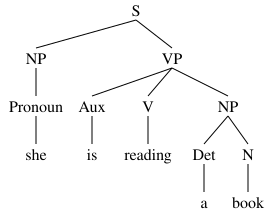

In [25]:

import nltk
from nltk import CFG
from nltk.parse import ChartParser
from nltk import Tree
from IPython.display import display

grammar = CFG.fromstring("""
S -> NP VP

NP -> Det N
NP -> Det Adj N
NP -> Det Adj N N
NP -> Adj N N
NP -> ProperN
NP -> Pronoun

VP -> V
VP -> V PP
VP -> V NP
VP -> V NP Adv
VP -> Aux V
VP -> Aux V NP
VP -> Aux V PP

PP -> Prep NP

Det -> 'the' | 'a'
N -> 'cat' | 'mat' | 'students' | 'language'
N -> 'processing' | 'laptop' | 'flowers' | 'garden' | 'book'
Adj -> 'beautiful' | 'new' | 'natural'
V -> 'sleeps' | 'studying' | 'bought' | 'growing' | 'reading'
Aux -> 'are' | 'is'
Prep -> 'on' | 'in'
ProperN -> 'john'
Pronoun -> 'she'
Adv -> 'yesterday'
""")

parser = ChartParser(grammar)

print("PHRASE STRUCTURE TREES\n")

for sentence in sentences:

    print("\nSentence:", sentence)

    tokens = word_tokenize(sentence.lower())

    # Remove punctuation
    tokens = [word for word in tokens if word.isalpha()]

    trees = list(parser.parse(tokens))

    if trees:
        for tree in trees:
            print("\nTree:")
            tree.pretty_print()
            display(tree)
    else:
        print("Cannot parse sentence.")
